# Генерация синтетических данных с использованием Faker

In [1]:
%pip install faker networkx matplotlib owlready2 -q

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import random
from faker import Faker
from datetime import datetime, timedelta

In [3]:
# Инициализация генератора (русская локаль для реалистичных ФИО, адресов и т.д.)
fake = Faker('ru_RU')
Faker.seed(42)      # фиксируем seed для воспроизводимости
random.seed(42)

## Генерация синтетических данных для варианта "Сотрудники компании"

In [4]:
# DataFrame с отделами
def generate_departments(n):
   
    departments = []
    for i in range(1, n + 1):
        departments.append({
            'department_id': i,
            'name': fake.unique.job() + ' отдел',  # уникальное название
            'location': fake.city()
        })
    return pd.DataFrame(departments)

# DataFrame с должностями и диапазоном зарплат
def generate_positions(n: int) -> pd.DataFrame:
    
    positions = []
    for i in range(1, n + 1):
        min_salary = random.randint(30000, 60000)
        max_salary = min_salary + random.randint(20000, 80000)
        positions.append({
            'position_id': i,
            'name': fake.unique.job(),
            'min_salary': min_salary,
            'max_salary': max_salary
        })
    return pd.DataFrame(positions)

# генерируем сотрудников со случайными атрибутами
def generate_employees(n: int, department_ids: list, position_ids: list) -> pd.DataFrame:
    
    employees = []
    for emp_id in range(1, n + 1):        
        first_name = fake.first_name()
        last_name = fake.last_name()
        patronymic = fake.middle_name()
        birth_date = fake.date_of_birth(minimum_age=18, maximum_age=70)
        phone = fake.phone_number()
        email = fake.email()
        address = fake.address().replace('\n', ', ')
        
        # дата найма: не раньше 18-летия и не позже сегодняшнего дня
        min_hire_date = birth_date + timedelta(days=18*365)
        hire_date = fake.date_between(start_date=min_hire_date, end_date='today')
        
        # статус -  active / terminated (10% уволены)
        status = random.choices(['active', 'terminated'], weights=[0.9, 0.1])[0]
        
        # выбор отдела и должности
        department_id = random.choice(department_ids)
        position_id = random.choice(position_ids)
        
        # зарплата     
        salary = random.randint(40000, 150000)
        
        employees.append({
            'employee_id': emp_id,
            'last_name': last_name,
            'first_name': first_name,
            'patronymic': patronymic,
            'birth_date': birth_date,
            'gender': random.choice(['М', 'Ж']),
            'address': address,
            'phone': phone,
            'email': email,
            'hire_date': hire_date,
            'status': status,
            'department_id': department_id,
            'position_id': position_id,
            'salary': salary
        })
    return pd.DataFrame(employees)

# создать историю зарплат на основе данных сотрудников
def generate_salary_history(employees_df: pd.DataFrame, avg_records: int = 3):    
    history = []
    record_id = 1
    
    for _, emp in employees_df.iterrows():
        emp_id = emp['employee_id']
        hire_date = emp['hire_date']
        current_salary = emp['salary']
        
        # количество изменений (0 – если сотрудник только нанят и ещё не было изменений)
        num_changes = random.choices([0, 1, 2, 3, 4], weights=[0.2, 0.3, 0.3, 0.1, 0.1])[0]
        
        # генерируем даты изменений (после hire_date и до сегодня)
        change_dates = sorted([fake.date_between(start_date=hire_date, end_date='today') 
                               for _ in range(num_changes)])
        
        # начальная зарплата при найме (можно сделать немного отличающейся от текущей)
        #  будем считать, что первая запись – это зарплата при найме,
        # а последующие – повышения.
        if num_changes == 0:
            # Если изменений не было, всё равно добавим одну запись (начальная)
            history.append({
                'history_id': record_id,
                'employee_id': emp_id,
                'change_date': hire_date,
                'new_salary': current_salary
            })
            record_id += 1
        else:
            # генерируем возрастающие зарплаты
            salary_values = sorted([random.randint(30000, current_salary) for _ in range(num_changes)])
            # добавляем текущую зарплату как последнюю
            salary_values.append(current_salary)
            # даты: hire_date и change_dates
            all_dates = [hire_date] + change_dates
            for i in range(len(all_dates)):
                history.append({
                    'history_id': record_id,
                    'employee_id': emp_id,
                    'change_date': all_dates[i],
                    'new_salary': salary_values[i]
                })
                record_id += 1
    return pd.DataFrame(history)

In [5]:
N_DEPARTMENTS = 10
N_POSITIONS = 20
N_EMPLOYEES = 500

In [6]:
departments_df = generate_departments(N_DEPARTMENTS)
positions_df = generate_positions(N_POSITIONS)
employees_df = generate_employees(
    N_EMPLOYEES,
    departments_df['department_id'].tolist(),
    positions_df['position_id'].tolist()
)

In [7]:
departments_df

,department_id,name,location
0,1,Диетолог отдел,клх Кырен
1,2,Метеоролог отдел,п. Волоколамск
2,3,Гепатолог отдел,г. Артем
3,4,Гомеопат отдел,п. Териберка
4,5,Бактериолог отдел,клх Усинск
5,6,Танцор отдел,с. Чикола
6,7,Нотариус отдел,ст. Ессентуки
7,8,Тележурналист отдел,к. Ельня
8,9,Литейщик отдел,г. Видное
9,10,Сиделка отдел,к. Нефедова


In [8]:
positions_df

,position_id,name,min_salary,max_salary
0,1,Мясник,50952,78248
1,2,Борт-радист,30819,99417
2,3,Философ,39012,75061
3,4,Доярка,37314,66458
4,5,Семейный врач,54132,80849
5,6,Врач скорой помощи,52174,120714
6,7,Ортопед,59234,114975
7,8,Реставратор,32848,91546
8,9,Композитор,43825,65907
9,10,Военный прокурор,30976,57116


In [9]:
employees_df

,employee_id,last_name,first_name,patronymic,birth_date,gender,address,phone,email,hire_date,status,department_id,position_id,salary
0,1,Гаврилов,Мина,Кузьминична,1969-12-01,М,"к. Бологое, пер. Островского, д. 77, 242388",+7 928 327 64 83,tatjana_03@example.org,1998-02-11,active,7,11,76421
1,2,Гордеев,Фотий,Владимировна,1976-12-07,Ж,"д. Александров Гай, бул. Донской, д. 6 стр. 34...",+7 (287) 101-2269,blinovnaum@example.net,2022-08-23,active,6,4,52156
2,3,Крюкова,Лаврентий,Егоровна,1982-09-03,М,"п. Хасавюрт, ул. Вахитова, д. 382, 824896",+7 (252) 880-9570,gushchinmitofan@example.com,2025-11-02,active,6,20,74671
3,4,Лукина,Тимур,Николаевна,1992-05-01,М,"г. Яхрома, алл. Профсоюзная, д. 951, 473829",+76578713315,safonovataisija@example.org,2019-10-18,active,9,4,89615
4,5,Капустина,Илья,Харламович,1998-07-26,М,"п. Уварово, алл. Челюскинцев, д. 84 к. 81, 080132",+7 (116) 566-7010,varhipova@example.org,2020-09-14,active,10,12,115674
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,496,Зыкова,Изот,Владленович,1972-12-30,Ж,"п. Палана, алл. Южная, д. 5 к. 8, 279970",8 398 358 4461,marfa2006@example.net,1997-09-01,active,4,16,112173
496,497,Бобылев,Демид,Арсеньевич,1964-05-10,М,"п. Ноглики, бул. Трактовый, д. 12 к. 848, 888975",8 397 871 3752,spartak_1983@example.org,2012-09-17,active,8,16,100401
497,498,Овчинникова,Иванна,Ниловна,1993-02-17,Ж,"г. Сковородино, наб. Тополиная, д. 29, 292950",8 852 386 0030,ladislav36@example.net,2012-07-25,active,6,6,58344
498,499,Пестов,Евстафий,Елизарович,1990-06-02,М,"г. Яшкуль, бул. Деповский, д. 232, 672019",8 (309) 309-6713,vadim2004@example.org,2022-07-27,active,9,2,108674


In [10]:
# Генерация истории зарплат
salary_history_df = generate_salary_history(employees_df, avg_records=3)
salary_history_df

,history_id,employee_id,change_date,new_salary
0,1,1,1998-02-11,71333
1,2,1,2014-02-11,76421
2,3,2,2022-08-23,34948
3,4,2,2024-04-08,52156
4,5,3,2025-11-02,74671
...,...,...,...,...
1291,1292,498,2024-11-16,57426
1292,1293,498,2025-09-09,58344
1293,1294,499,2022-07-27,89827
1294,1295,499,2025-07-22,108674


In [11]:
# Сохранение в CSV
departments_df.to_csv('departments.csv', index=False)
positions_df.to_csv('positions.csv', index=False)
employees_df.to_csv('employees.csv', index=False)
salary_history_df.to_csv('salary_history.csv', index=False)

# Задание на самостоятельную работу
Создать синтетический набор данных, сохранить его в csv файлы, построить на основе данных онтологию, вывести онтограф.


### Вариант 1. Аренда электромобилей
Сущности: 
- Автомобиль: id, марка, модель, год выпуска, госномер, запас хода (км), статус (доступен, арендован, на обслуживании), тариф (цена за минуту), локация (парковка). История зарядок (JSON-массив объектов: {id станции, дата_начала, дата_конца, объём_кВт·ч, стоимость}).
- Клиент: id, ФИО, водительское удостоверение (серия, номер), телефон, email, дата регистрации.
- Аренда:id, id клиента, id автомобиля, дата и время начала, дата и время окончания, начальный пробег, конечный пробег, стоимость, статус (активна, завершена, отменена), Информация об оплате (поля внутри таблицы): сумма, способ оплаты, дата оплаты, статус оплаты.
- Зарядная станция: id, адрес, тип разъёма, количество мест, статус (работает/не работает).

Объём данных: автомобили - 100, клиенты - 500, аренды - 3000, зарядные станции -  20

Онтология:
- Классы: Автомобиль, Клиент, Аренда, ЗаряднаяСтанция.
- Связи:  клиент арендует автомобиль, автомобиль участвует в арендах, история зарядок хранится в JSON внутри автомобиля, ссылаясь на станции, Аренда содержит данные об оплате.

### Вариант 2. Банковские клиенты и транзакции
Сущности: 
- Клиент: id, ФИО, дата рождения, паспортные данные (серия, номер, кем выдан), адрес, телефон, email.
- Счёт: id, номер счёта, тип (дебетовый/кредитный), валюта, дата открытия, остаток, id клиента.
- Транзакция: id, дата, сумма, тип (пополнение/списание), id счёта, описание.
- Кредит: id, id клиента, сумма, процентная ставка, срок, дата выдачи, ежемесячный платёж.

Объём: 1000 клиентов, у каждого 1–3 счёта, на каждом 10–50 транзакций, 20% клиентов имеют кредиты.

Онтология:
- Классы: Клиент, Счёт, Транзакция, Кредит.
- Связи: клиент владеет счетами, по счетам проходят транзакции, клиент может иметь кредиты.

### Вариант 3. Медицинские пациенты и приёмы
Сущности:
- Пациент: id, ФИО, дата рождения, пол, полис ОМС, СНИЛС, адрес, телефон.
- Врач: id, ФИО, специальность, кабинет.
- Приём: id, дата и время, id пациента, id врача, диагноз (код МКБ-10), жалобы, назначения (JSON-массив объектов: {лекарство, дозировка, курс}).
- Больничный лист: id, id приёма, дата начала, дата окончания, диагноз.

Объём: 2000 пациентов, 50 врачей, 5–10 приёмов на пациента за последние 2 года, часть с больничными.

Онтология:
- Классы: Пациент, Врач, Приём, БольничныйЛист.
- Связи: пациент посещает врача (приём), по приёму может быть открыт больничный, назначения хранятся в JSON приёма (Атрибут класса Прием).

### Вариант 4. Студенты и успеваемость
Сущности:
- Студент: id, ФИО, дата рождения, группа, год поступления, форма обучения.
- Группа: id, номер, курс, институт, направление подготовки.
- Предмет: id, название, семестр, количество часов, форма контроля (экзамен/зачёт), id преподавателя.
- Оценка: id, id студента, id предмета, дата, оценка (число или зачёт/незачёт).
- Преподаватель: id, ФИО, кафедра.

Объём: 10 групп по 25 студентов = 250 студентов, 30 предметов, у каждого студента оценки по всем предметам (≈ 7500 записей).

Онтология
- Классы: Студент, Группа, Предмет, Оценка, Преподаватель.
- Связи: студент учится в группе, группа изучает предметы (связка группа-предмет), преподаватель ведёт предмет, студент получает оценки.

### Вариант 5. Интернет-магазин: товары, заказы, покупатели
Сущности:
- Покупатель: id, email, ФИО, телефон, дата регистрации.
- Товар: id, название, категория, цена, остаток на складе.
- Заказ: id, id покупателя, дата, статус (новый, оплачен, отгружен, доставлен).
- Состав заказа: id заказа, id товара, количество, цена в момент заказа.
- Отзыв: id, id покупателя, id товара, оценка (1–5), текст, дата.

Объём: 500 покупателей, 1000 товаров, 3000 заказов (в среднем по 2 товара в заказе), 1500 отзывов.

Онтология:
- Классы: Покупатель, Товар, Заказ, СтрокаЗаказа, Отзыв.
- Связи: покупатель делает заказ, заказ содержит товары (с количеством), покупатель оставляет отзыв на товар.

### Вариант 6. Недвижимость и сделки
Сущности: 
- Объект недвижимости: id, адрес, тип (квартира/дом/коммерческое), площадь, количество комнат, этаж, год постройки, кадастровый номер.
- Владелец: id, ФИО, паспортные данные, доля (если долевая собственность).
- Сделка купли-продажи: id, дата, id объекта, id продавца, id покупателя, цена, нотариус.
- Ценовой архив: id объекта, дата изменения, новая цена (для отслеживания динамики).

Объём: 2000 объектов, 300 владельцев, 150 сделок, у каждого объекта 2–3 записи цен.

Онтология:
- Классы: Объект, Владелец, Сделка, ЦеновойАрхив.
- Связи: объект может иметь нескольких владельцев (доли), сделка связывает продавца, покупателя и объект.

### Вариант 7. Транспортные средства и штрафы
Сущности:
- Владелец ТС: id, ФИО, водительское удостоверение (серия, номер), адрес, телефон.
- Автомобиль: id, госномер, марка, модель, год выпуска, VIN, цвет, id владельца.
- Штраф: id, id автомобиля, дата, статья нарушения, сумма, статус (оплачен/не оплачен).
- Страховой полис: id, id автомобиля, компания, дата начала, дата окончания, стоимость.

Объём: 1000 владельцев, 1200 автомобилей (некоторые владеют несколькими), 5000 штрафов, 1500 полисов.

Онтология:
- Классы: Владелец, Автомобиль, Штраф, Полис.
- Связи: владелец владеет автомобилями, автомобиль имеет штрафы и страховки.

### Вариант 8. Библиотека: книги, читатели, выдачи
Сущности:
- Книга: id, ISBN, название, автор, год издания, издательство, жанр, количество экземпляров в библиотеке.
- Читатель: id, ФИО, дата рождения, адрес, телефон, email, дата регистрации.
- Выдача: id, id книги, id читателя, дата выдачи, дата возврата (если есть), фактическая дата возврата.
- Бронь: id, id книги, id читателя, дата брони, статус (активна/исполнена).

Объём: 500 книг, 300 читателей, 2000 выдач, 100 броней.

Онтология:
- Классы: Книга, Читатель, Выдача, Бронь.
- Связи: читатель берёт книгу (выдача), может бронировать.

### Вариант 9. Техподдержка: заявки и обращения
Сущности:
- Пользователь: id, ФИО, email, телефон, уровень (обычный/премиум).
- Категория заявки: id, название, описание.
- Сотрудник поддержки: id, ФИО, отдел, количество решённых заявок.
- Заявка: id, id пользователя, id категории, тема, описание, дата создания, статус (новая, в работе, решена, закрыта), приоритет, id сотрудника (назначен), комментарии (JSON-массив объектов: {id автора (пользователь или сотрудник), текст, дата}).

Объём данных: пользователи - 1000, категории - 5, сотрудники - 10, заявки - 5000, комментарии - 15 000  (общее на все заявки)

Онтология:
- Классы: Пользователь, Категория, Сотрудник, Заявка.
- Связи: пользователь создаёт заявку; заявка относится к категории; заявка назначается сотруднику; комментарии принадлежат заявке (в JSON).

### Вариант 10. Доставка обедов из ресторанов
Сущности: 
- Ресторан: id, название, адрес, кухня (тип кухни), рейтинг.
- Блюдо: id, название, id ресторана, категория, цена, вес/порция, калории.
- Клиент: id, ФИО, телефон, email, адрес доставки (основной), дата регистрации.
- Заказ: id, id клиента, id ресторана, дата и время заказа, статус (принят, готовится, доставлен, отменён), общая сумма, способ оплаты, состав заказа (JSON-массив объектов: {id блюда, количество, цена_в_момент_заказа}), информация о доставке (поля внутри той же таблицы): курьер (ФИО), дата и время назначения курьера, дата и время фактической доставки, статус доставки (назначен, в пути, выполнен), фактический адрес доставки (если отличается от адреса клиента)

Объём данных: рестораны -  20, блюда - в среднем 20 на ресторан, клиенты -  1000, заказы - 5000.

Онтология: 
- Классы: Ресторан, Блюдо, Клиент, Заказ.
- Связи: ресторан предлагает блюда, клиент оформляет заказ, заказ ссылается на ресторан и клиента.

Состав заказа и данные доставки хранятся внутри сущности «Заказ» (денормализовано с использованием JSON).


# Выполнение самостоятельной работы: вариант 4. Студенты и успеваемость

Сущности: Студент, Группа, Предмет, Оценка, Преподаватель. Объём: 10 групп × 25 студентов = 250, 30 предметов, оценки каждого студента по всем предметам (7500 записей).

## 1. Генерация синтетических данных

In [12]:
# ===== Вариант 4. Студенты и успеваемость: генерация данных =====
N_GROUPS, STUDENTS_PER_GROUP, N_SUBJECTS, N_TEACHERS = 10, 25, 30, 12

INSTITUTES = {
    "Институт энергетики и автоматизированных систем": [("09.03.03", "Прикладная информатика"), ("09.03.01", "Информатика и вычислительная техника")],
    "Институт металлургии, машиностроения и материалообработки": [("22.03.02", "Металлургия"), ("15.03.01", "Машиностроение")],
    "Институт строительства, архитектуры и искусства": [("08.03.01", "Строительство"), ("07.03.01", "Архитектура")],
}
DEPARTMENTS = ["Кафедра информатики и информационной безопасности", "Кафедра вычислительной техники и программирования",
               "Кафедра математики", "Кафедра физики", "Кафедра иностранных языков",
               "Кафедра экономики", "Кафедра философии и истории"]
SUBJECT_NAMES = [
    "Высшая математика", "Линейная алгебра", "Теория вероятностей и статистика", "Дискретная математика", "Физика",
    "Программирование на Python", "Алгоритмы и структуры данных", "Базы данных", "Операционные системы", "Компьютерные сети",
    "Web-технологии", "Объектно-ориентированное программирование", "Проектирование информационных систем", "Тестирование ПО",
    "Информационная безопасность", "Большие данные", "Машинное обучение", "Основы искусственного интеллекта",
    "Английский язык", "Философия", "История России", "Экономика", "Менеджмент проектов", "Правоведение",
    "Безопасность жизнедеятельности", "Физическая культура", "Социология", "Психология", "Культурология", "Основы бизнеса"]
assert len(SUBJECT_NAMES) == N_SUBJECTS

PREFIX = {"Прикладная информатика": "АПИб", "Информатика и вычислительная техника": "ИВТб", "Металлургия": "МТб",
          "Машиностроение": "МШб", "Строительство": "СТб", "Архитектура": "АРб"}

def person(gender):
    """ФИО с согласованными по полу фамилией, именем и отчеством."""
    if gender == 'М':
        return fake.last_name_male(), fake.first_name_male(), fake.middle_name_male()
    return fake.last_name_female(), fake.first_name_female(), fake.middle_name_female()

def generate_teachers(n):
    rows = []
    for i in range(1, n + 1):
        g = random.choice(['М', 'Ж']); ln, fn, mn = person(g)
        rows.append({'teacher_id': i, 'last_name': ln, 'first_name': fn, 'patronymic': mn,
                     'department': DEPARTMENTS[(i - 1) % len(DEPARTMENTS)]})
    return pd.DataFrame(rows)

def generate_groups(n):
    rows = []
    for i in range(1, n + 1):
        institute = list(INSTITUTES)[(i - 1) % len(INSTITUTES)]
        code, direction = random.choice(INSTITUTES[institute])
        course = (i - 1) % 4 + 1
        rows.append({'group_id': i, 'number': f"{PREFIX[direction]}-{26 - course}-{(i - 1) // 4 + 1}",
                     'course': course, 'institute': institute,
                     'direction': f"{code} {direction}", 'admission_year': 2026 - course})
    return pd.DataFrame(rows)

def generate_subjects(teachers_df):
    rows = []
    for i, name in enumerate(SUBJECT_NAMES, 1):
        rows.append({'subject_id': i, 'name': name, 'semester': random.randint(1, 8),
                     'hours': random.choice([36, 54, 72, 108, 144]),
                     'control_form': random.choice(['экзамен', 'зачёт']),
                     'teacher_id': int(random.choice(teachers_df['teacher_id']))})
    return pd.DataFrame(rows)

def generate_students(groups_df, per_group):
    rows, sid = [], 1
    for _, grp in groups_df.iterrows():
        for _ in range(per_group):
            g = random.choice(['М', 'Ж']); ln, fn, mn = person(g)
            rows.append({'student_id': sid, 'last_name': ln, 'first_name': fn, 'patronymic': mn, 'gender': g,
                         'birth_date': fake.date_of_birth(minimum_age=17 + grp['course'], maximum_age=20 + grp['course']),
                         'group_id': int(grp['group_id']), 'admission_year': int(grp['admission_year']),
                         'study_form': random.choices(['очная', 'очно-заочная', 'заочная'], weights=[0.8, 0.12, 0.08])[0]})
            sid += 1
    return pd.DataFrame(rows)

def generate_group_subjects(groups_df, subjects_df):
    """Связка группа-предмет: каждая группа изучает все 30 предметов."""
    return pd.DataFrame([{'group_id': int(g), 'subject_id': int(s)}
                         for g in groups_df['group_id'] for s in subjects_df['subject_id']])

def generate_grades(students_df, subjects_df):
    """Оценка каждого студента по каждому предмету: экзамен -> 2..5, зачёт -> зачёт/незачёт."""
    rows, gid = [], 1
    for _, st in students_df.iterrows():
        ability = random.gauss(0, 1)          # "способности" студента: оценки по предметам коррелируют
        for _, sb in subjects_df.iterrows():
            if sb['control_form'] == 'экзамен':
                x = ability + random.gauss(0.3, 0.9)
                grade = 5 if x > 0.9 else 4 if x > 0 else 3 if x > -1.0 else 2
            else:
                grade = 'зачёт' if ability + random.gauss(0.8, 0.8) > -0.6 else 'незачёт'
            exam_date = fake.date_between(start_date=datetime(2025, 1, 10), end_date=datetime(2026, 6, 30))
            rows.append({'grade_id': gid, 'student_id': int(st['student_id']), 'subject_id': int(sb['subject_id']),
                         'date': exam_date, 'grade': grade})
            gid += 1
    return pd.DataFrame(rows)

In [13]:
# Фиксируем seed заново, чтобы данные варианта 4 воспроизводились независимо от предыдущих ячеек
Faker.seed(2026); random.seed(2026)
teachers_df       = generate_teachers(N_TEACHERS)
groups_df         = generate_groups(N_GROUPS)
subjects_df       = generate_subjects(teachers_df)
students_df       = generate_students(groups_df, STUDENTS_PER_GROUP)
group_subjects_df = generate_group_subjects(groups_df, subjects_df)
grades_df         = generate_grades(students_df, subjects_df)

for name, df in [("teachers", teachers_df), ("groups", groups_df), ("subjects", subjects_df), ("students", students_df),
                 ("group_subjects", group_subjects_df), ("grades", grades_df)]:
    df.to_csv(f"{name}.csv", index=False, encoding="utf-8")
    print(f"{name}.csv: {len(df)} записей")

teachers.csv: 12 записей
groups.csv: 10 записей
subjects.csv: 30 записей
students.csv: 250 записей
group_subjects.csv: 300 записей
grades.csv: 7500 записей


Проверка объёмов и целостности ссылок (внешних ключей):

In [14]:
# Проверка целостности и объёмов
assert len(groups_df) == 10 and len(students_df) == 250 and len(subjects_df) == 30
assert (students_df.groupby('group_id').size() == 25).all()
assert len(grades_df) == 250 * 30 == 7500
assert grades_df.groupby('student_id')['subject_id'].nunique().eq(30).all()      # оценки по всем предметам
assert set(subjects_df['teacher_id']) <= set(teachers_df['teacher_id'])           # ссылки на преподавателей
assert set(students_df['group_id']) <= set(groups_df['group_id'])
# оценка соответствует форме контроля
g = grades_df.merge(subjects_df[['subject_id', 'control_form']], on='subject_id')
assert g.loc[g.control_form == 'экзамен', 'grade'].isin([2, 3, 4, 5, '2', '3', '4', '5']).all()
assert g.loc[g.control_form == 'зачёт', 'grade'].isin(['зачёт', 'незачёт']).all()
print("Все проверки пройдены")
print(grades_df['grade'].astype(str).value_counts().to_string())

Все проверки пройдены
grade
зачёт      3686
5          1106
4           868
3           755
незачёт     564
2           521


In [15]:
display(groups_df)
display(students_df.head())
display(subjects_df.head())
display(grades_df.head())

,group_id,number,course,institute,direction,admission_year
0,1,АПИб-25-1,1,Институт энергетики и автоматизированных систем,09.03.03 Прикладная информатика,2025
1,2,МШб-24-1,2,"Институт металлургии, машиностроения и материа...",15.03.01 Машиностроение,2024
2,3,СТб-23-1,3,"Институт строительства, архитектуры и искусства",08.03.01 Строительство,2023
3,4,ИВТб-22-1,4,Институт энергетики и автоматизированных систем,09.03.01 Информатика и вычислительная техника,2022
4,5,МШб-25-2,1,"Институт металлургии, машиностроения и материа...",15.03.01 Машиностроение,2025
5,6,СТб-24-2,2,"Институт строительства, архитектуры и искусства",08.03.01 Строительство,2024
6,7,ИВТб-23-2,3,Институт энергетики и автоматизированных систем,09.03.01 Информатика и вычислительная техника,2023
7,8,МШб-22-2,4,"Институт металлургии, машиностроения и материа...",15.03.01 Машиностроение,2022
8,9,АРб-25-3,1,"Институт строительства, архитектуры и искусства",07.03.01 Архитектура,2025
9,10,ИВТб-24-3,2,Институт энергетики и автоматизированных систем,09.03.01 Информатика и вычислительная техника,2024


,student_id,last_name,first_name,patronymic,gender,birth_date,group_id,admission_year,study_form
0,1,Владимирова,Лукия,Богдановна,Ж,2006-12-31,1,2025,очная
1,2,Калинин,Константин,Фокич,М,2005-05-01,1,2025,очная
2,3,Юдина,Ульяна,Константиновна,Ж,2004-11-13,1,2025,очная
3,4,Рогова,Маргарита,Михайловна,Ж,2006-08-12,1,2025,очно-заочная
4,5,Тарасов,Нифонт,Эдуардович,М,2008-03-28,1,2025,очная


,subject_id,name,semester,hours,control_form,teacher_id
0,1,Высшая математика,7,144,экзамен,12
1,2,Линейная алгебра,6,36,зачёт,5
2,3,Теория вероятностей и статистика,8,54,зачёт,1
3,4,Дискретная математика,6,72,зачёт,7
4,5,Физика,2,108,зачёт,2


,grade_id,student_id,subject_id,date,grade
0,1,1,1,2025-09-03,4
1,2,1,2,2025-12-09,зачёт
2,3,1,3,2025-04-11,зачёт
3,4,1,4,2025-04-08,зачёт
4,5,1,5,2025-04-26,зачёт


## 2. Построение онтологии

Классы: Студент, Группа, Предмет, Оценка, Преподаватель. Связи: студент учится в группе, группа изучает предметы, преподаватель ведёт предмет, студент получает оценки (оценка относится к предмету). Онтология сохраняется в `student_performance.owl`.

In [16]:
# ===== Онтология варианта 4 =====
from owlready2 import *

onto = get_ontology("http://test.org/student_performance.owl")
with onto:
    class Студент(Thing): pass
    class Группа(Thing): pass
    class Предмет(Thing): pass
    class Оценка(Thing): pass
    class Преподаватель(Thing): pass

    # Связи (ObjectProperty)
    class учится_в_группе(ObjectProperty):      # студент -> группа
        domain = [Студент]; range = [Группа]
    class изучает_предмет(ObjectProperty):      # группа -> предмет (связка группа-предмет)
        domain = [Группа]; range = [Предмет]
    class ведёт_предмет(ObjectProperty):        # преподаватель -> предмет
        domain = [Преподаватель]; range = [Предмет]
    class получает_оценку(ObjectProperty):      # студент -> оценка
        domain = [Студент]; range = [Оценка]
    class оценка_по_предмету(ObjectProperty):   # оценка -> предмет
        domain = [Оценка]; range = [Предмет]

    # Атрибуты (DataProperty)
    class фио(DataProperty):             range = [str]
    class дата_рождения(DataProperty):   range = [str]
    class год_поступления(DataProperty): range = [int]
    class форма_обучения(DataProperty):  range = [str]
    class номер_группы(DataProperty):    range = [str]
    class курс(DataProperty):            range = [int]
    class институт(DataProperty):        range = [str]
    class направление(DataProperty):     range = [str]
    class название(DataProperty):        range = [str]
    class семестр(DataProperty):         range = [int]
    class часов(DataProperty):           range = [int]
    class форма_контроля(DataProperty):  range = [str]
    class кафедра(DataProperty):         range = [str]
    class значение_оценки(DataProperty): range = [str]
    class дата_оценки(DataProperty):     range = [str]

def fio_of(r): return f"{r['last_name']} {r['first_name']} {r['patronymic']}"

with onto:
    teachers = {}
    for _, r in teachers_df.iterrows():
        t = Преподаватель(f"преподаватель_{r.teacher_id}"); t.фио = [fio_of(r)]; t.кафедра = [r.department]
        teachers[r.teacher_id] = t
    groups = {}
    for _, r in groups_df.iterrows():
        g = Группа(f"группа_{r.group_id}"); g.номер_группы = [r.number]; g.курс = [int(r.course)]
        g.институт = [r.institute]; g.направление = [r.direction]
        groups[r.group_id] = g
    subjects = {}
    for _, r in subjects_df.iterrows():
        s = Предмет(f"предмет_{r.subject_id}"); s.название = [r['name']]; s.семестр = [int(r.semester)]
        s.часов = [int(r.hours)]; s.форма_контроля = [r.control_form]
        subjects[r.subject_id] = s
        teachers[r.teacher_id].ведёт_предмет.append(s)
    for _, r in group_subjects_df.iterrows():
        groups[r.group_id].изучает_предмет.append(subjects[r.subject_id])
    students = {}
    for _, r in students_df.iterrows():
        st = Студент(f"студент_{r.student_id}"); st.фио = [fio_of(r)]; st.дата_рождения = [str(r.birth_date)]
        st.год_поступления = [int(r.admission_year)]; st.форма_обучения = [r.study_form]
        st.учится_в_группе = [groups[r.group_id]]
        students[r.student_id] = st
    for _, r in grades_df.iterrows():
        o = Оценка(f"оценка_{r.grade_id}"); o.значение_оценки = [str(r.grade)]; o.дата_оценки = [str(r.date)]
        o.оценка_по_предмету = [subjects[r.subject_id]]
        students[r.student_id].получает_оценку.append(o)

onto.save(file="student_performance.owl", format="rdfxml")
for c in (Студент, Группа, Предмет, Оценка, Преподаватель):
    print(f"{c.name}: {len(list(c.instances()))} индивидов")

Студент: 250 индивидов
Группа: 10 индивидов
Предмет: 30 индивидов
Оценка: 7500 индивидов
Преподаватель: 12 индивидов


In [17]:
# Примеры запросов к онтологии
st = students[1]
print("Студент:", st.фио[0], "| группа:", st.учится_в_группе[0].номер_группы[0])
print("Оценок у студента:", len(st.получает_оценку))
for o in st.получает_оценку[:5]:
    p = o.оценка_по_предмету[0]
    prof = [t.фио[0] for t in onto.Преподаватель.instances() if p in t.ведёт_предмет]
    print(f"  {p.название[0]:45s} {o.значение_оценки[0]:8s} преподаватель: {prof[0]}")
print("Предметов у группы 1:", len(groups[1].изучает_предмет))

Студент: Владимирова Лукия Богдановна | группа: АПИб-25-1
Оценок у студента: 30
  Высшая математика                             4        преподаватель: Кононова Раиса Анатольевна
  Линейная алгебра                              зачёт    преподаватель: Ситникова Феврония Павловна
  Теория вероятностей и статистика              зачёт    преподаватель: Ковалев Лучезар Юлианович
  Дискретная математика                         зачёт    преподаватель: Федорова Валерия Ильинична
  Физика                                        зачёт    преподаватель: Селиверстова Раиса Борисовна
Предметов у группы 1: 30


## 3. Онтограф

Сначала схема онтологии (классы, связи, атрибуты), затем граф индивидов на фрагменте данных.

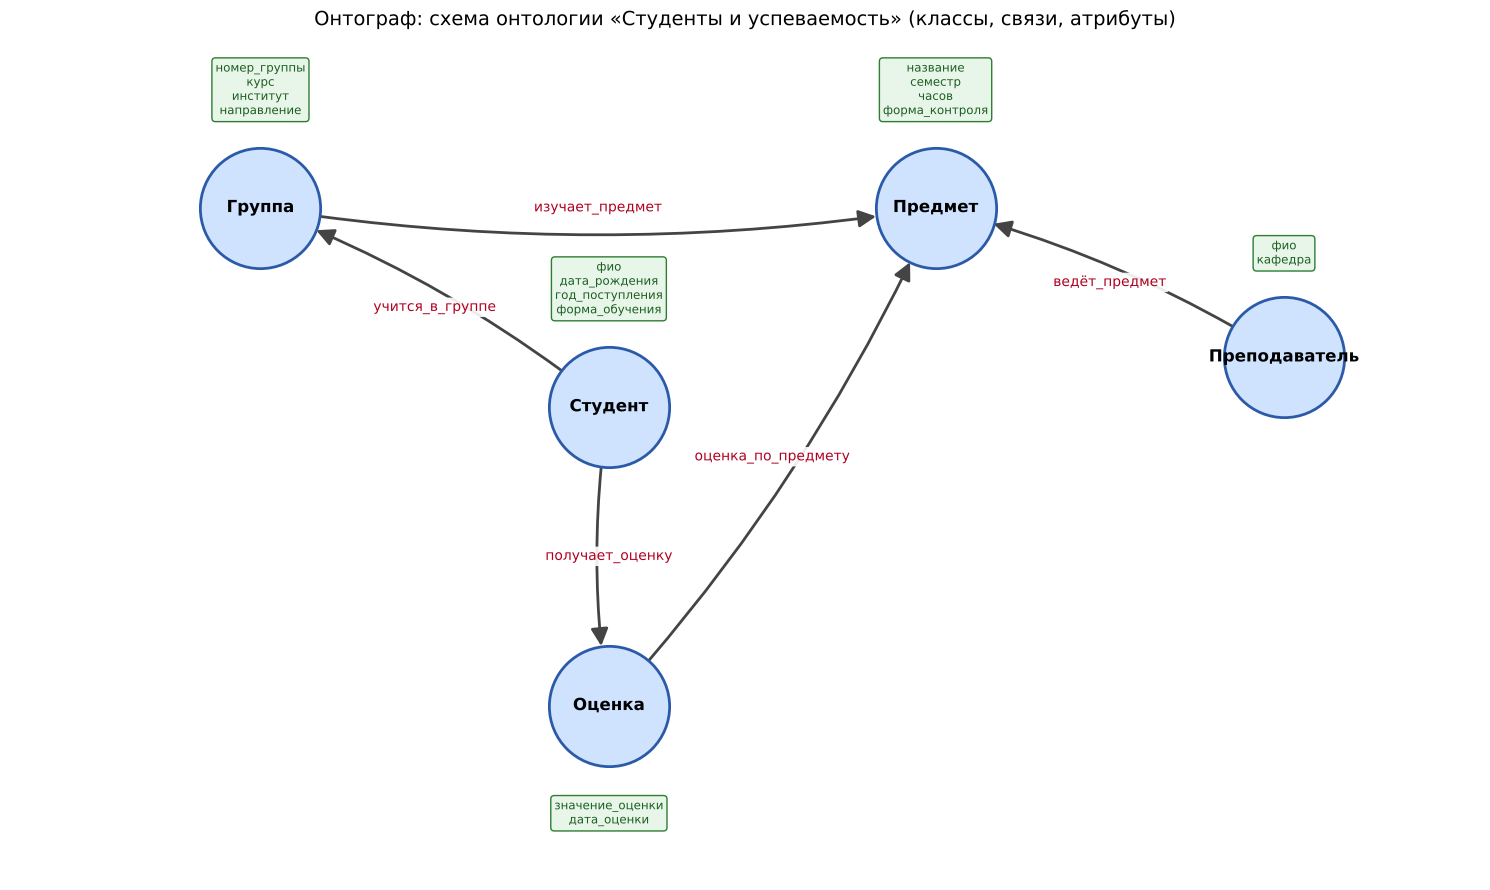

In [18]:
# ===== Онтограф =====
import networkx as nx
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'DejaVu Sans'

# --- 1. Схема онтологии (классы, связи и атрибуты) ---
classes = ["Студент", "Группа", "Предмет", "Оценка", "Преподаватель"]
relations = [("Студент", "Группа", "учится_в_группе"), ("Группа", "Предмет", "изучает_предмет"),
             ("Преподаватель", "Предмет", "ведёт_предмет"), ("Студент", "Оценка", "получает_оценку"),
             ("Оценка", "Предмет", "оценка_по_предмету")]
attrs = {"Студент": ["фио", "дата_рождения", "год_поступления", "форма_обучения"],
         "Группа": ["номер_группы", "курс", "институт", "направление"],
         "Предмет": ["название", "семестр", "часов", "форма_контроля"],
         "Оценка": ["значение_оценки", "дата_оценки"], "Преподаватель": ["фио", "кафедра"]}
pos = {"Студент": (0, 0), "Группа": (-3.2, 1.6), "Предмет": (3.0, 1.6), "Оценка": (0, -2.4), "Преподаватель": (6.2, 0.4)}

fig, ax = plt.subplots(figsize=(15, 9))
G = nx.DiGraph(); G.add_nodes_from(classes); G.add_edges_from([(a, b) for a, b, _ in relations])
nx.draw_networkx_nodes(G, pos, node_size=7500, node_color="#cfe3ff", edgecolors="#2b5aa8", linewidths=2, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=12, font_weight="bold", ax=ax)
nx.draw_networkx_edges(G, pos, arrowsize=26, width=2, edge_color="#444", node_size=7500,
                       connectionstyle="arc3,rad=0.08", ax=ax)
nx.draw_networkx_edge_labels(G, pos, edge_labels={(a, b): l for a, b, l in relations}, font_size=10,
                             font_color="#b00020", label_pos=0.5, rotate=False, ax=ax,
                             bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.9))
for c, lst in attrs.items():
    x, y = pos[c]
    dy = -0.55 if c in ("Оценка",) else 0.62
    ax.text(x, y + (-0.75 if c == "Оценка" else 0.72), "\n".join(lst), ha="center",
            va="top" if c == "Оценка" else "bottom", fontsize=8.5, color="#1b5e20",
            bbox=dict(boxstyle="round,pad=0.3", fc="#e8f5e9", ec="#2e7d32"))
ax.set_title("Онтограф: схема онтологии «Студенты и успеваемость» (классы, связи, атрибуты)", fontsize=14)
ax.set_xlim(-5.5, 8); ax.set_ylim(-3.8, 3.0); ax.axis("off")
plt.tight_layout(); plt.savefig("ontograph_schema.png", dpi=130); plt.show()

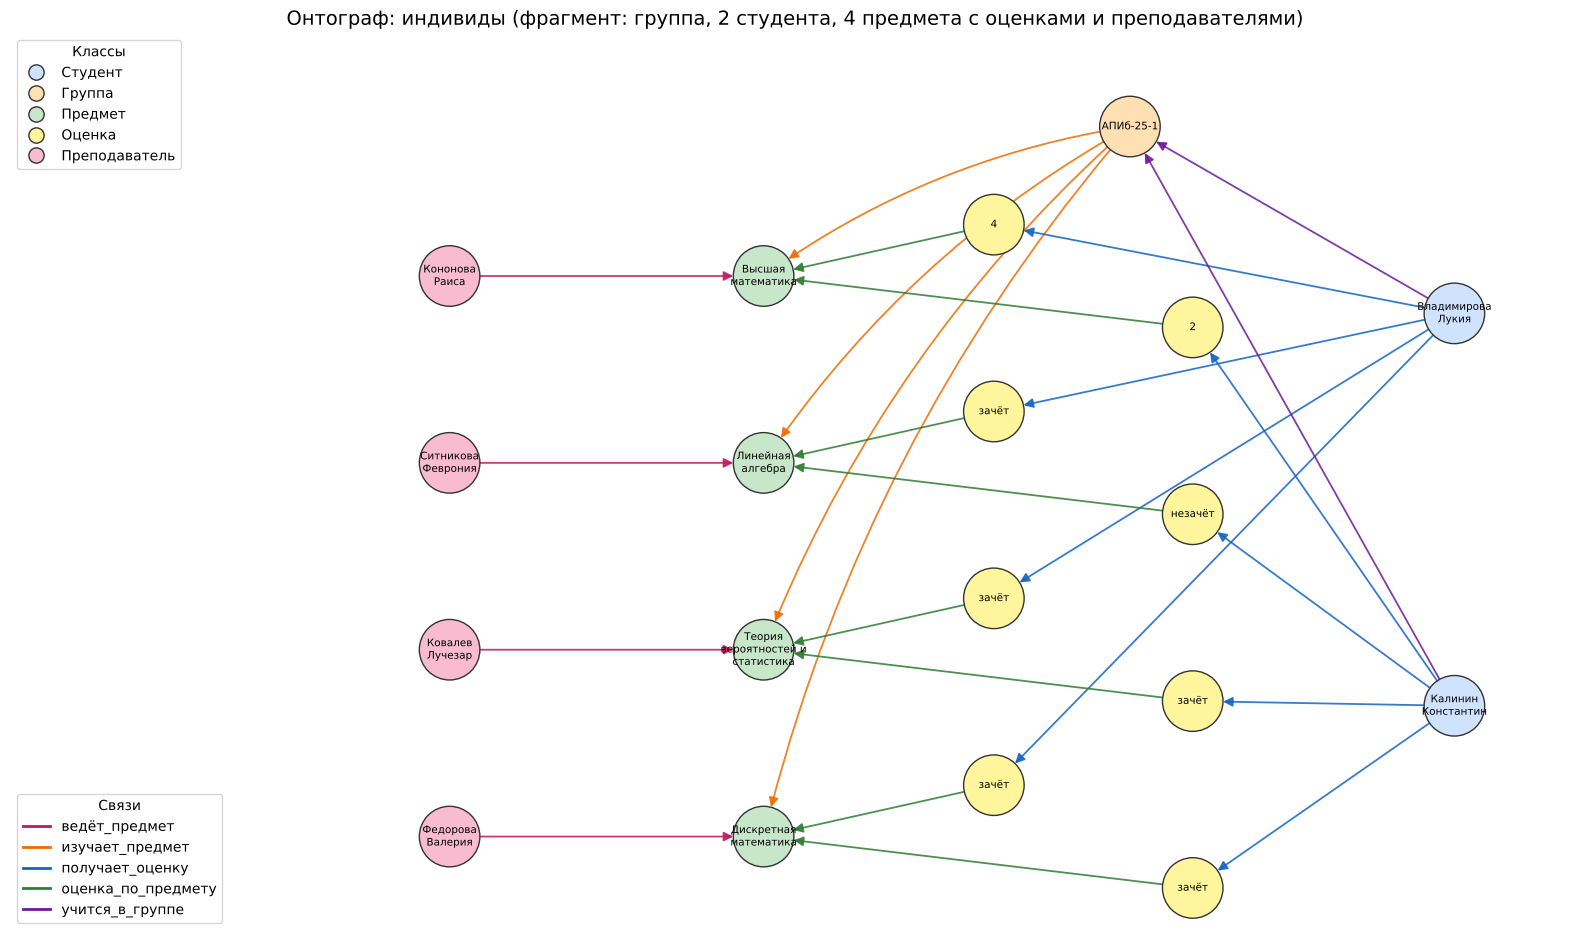

In [19]:
# --- 2. Онтограф на уровне индивидов: фрагмент данных (1 группа, 2 студента, 4 предмета) ---
grp = groups[1]
stud = [s for s in onto.Студент.instances() if s.учится_в_группе[0] is grp][:2]
subj = list(grp.изучает_предмет)[:4]
teach = {p: next(t for t in onto.Преподаватель.instances() if p in t.ведёт_предмет) for p in subj}

pos2, label, kind, edges = {}, {}, {}, []
def node(n, k, text, xy): pos2[n.name] = xy; label[n.name] = text; kind[n.name] = k
short = lambda f: " ".join(f.split()[:2])
for j, p in enumerate(subj):
    y = (len(subj) - 1 - j) * 2.0
    node(p, "Предмет", "\n".join(__import__("textwrap").wrap(p.название[0], 14)), (3, y))
    t = teach[p]; node(t, "Преподаватель", short(t.фио[0]).replace(" ", "\n"), (0, y))
    edges.append((t.name, p.name, "ведёт_предмет")); edges.append((grp.name, p.name, "изучает_предмет"))
node(grp, "Группа", grp.номер_группы[0], (6.5, 7.6))
for k, s in enumerate(stud):
    ys = []
    for j, p in enumerate(subj):
        o = next(o for o in s.получает_оценку if o.оценка_по_предмету[0] is p)
        y = (len(subj) - 1 - j) * 2.0 + (0.55 if k == 0 else -0.55)
        node(o, "Оценка", o.значение_оценки[0], (6 + 1.8 * k - 0.0, y) if False else (5.2 + 1.9 * k, y)); ys.append(y)
        edges.append((s.name, o.name, "получает_оценку")); edges.append((o.name, p.name, "оценка_по_предмету"))
    node(s, "Студент", short(s.фио[0]).replace(" ", "\n"), (9.6, 5.6 if k == 0 else 1.4))
    edges.append((s.name, grp.name, "учится_в_группе"))

palette = {"Студент": "#cfe3ff", "Группа": "#ffe0b2", "Предмет": "#c8e6c9", "Оценка": "#fff59d", "Преподаватель": "#f8bbd0"}
ecol = {"ведёт_предмет": "#c2185b", "изучает_предмет": "#ef6c00", "получает_оценку": "#1565c0",
        "оценка_по_предмету": "#2e7d32", "учится_в_группе": "#6a1b9a"}
fig, ax = plt.subplots(figsize=(16, 9.5))
G2 = nx.DiGraph(); G2.add_nodes_from(pos2)
for a, b, l in edges:
    nx.draw_networkx_edges(G2, pos2, edgelist=[(a, b)], edge_color=ecol[l], arrows=True, arrowsize=14, width=1.3, alpha=.85,
                           node_size=1900, ax=ax, connectionstyle="arc3,rad=0.12" if l == "изучает_предмет" else "arc3,rad=0.0")
nx.draw_networkx_nodes(G2, pos2, node_size=1900, node_color=[palette[kind[n]] for n in G2], edgecolors="#333", ax=ax)
nx.draw_networkx_labels(G2, pos2, labels=label, font_size=7.5, ax=ax)
h1 = [plt.Line2D([], [], marker="o", ls="", color=c, mec="#333", ms=11, label=k) for k, c in palette.items()]
h2 = [plt.Line2D([], [], color=c, lw=2, label=l) for l, c in ecol.items()]
leg1 = ax.legend(handles=h1, loc="upper left", title="Классы", fontsize=10); ax.add_artist(leg1)
ax.legend(handles=h2, loc="lower left", title="Связи", fontsize=10)
ax.set_title("Онтограф: индивиды (фрагмент: группа, 2 студента, 4 предмета с оценками и преподавателями)", fontsize=14)
ax.set_xlim(-4.2, 10.8); ax.set_ylim(-1, 8.6); ax.axis("off"); plt.tight_layout(); plt.savefig("ontograph_instances.png", dpi=130); plt.show()

## Вывод

Сгенерированы 6 CSV-файлов (преподаватели, группы, предметы, студенты, связка группа-предмет, оценки), на их основе построена онтология с 5 классами и 5 связями и выведены онтографы.